In [1]:
# ============================================================
# CELL 1 — Imports
# ============================================================
import numpy as np
import time
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from torchvision import datasets
import random

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

2026-05-11 13:53:10.412599: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778507590.918343      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778507591.051555      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778507592.155095      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778507592.155131      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778507592.155134      57 computation_placer.cc:177] computation placer alr

TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# ============================================================
# CELL 2 — Load MNIST
# ============================================================
train_dataset_full = datasets.MNIST(root='./data', train=True,  download=True)
test_dataset_full  = datasets.MNIST(root='./data', train=False, download=True)

train_images_full = train_dataset_full.data.numpy()
train_labels_full = train_dataset_full.targets.numpy()
test_images_full  = test_dataset_full.data.numpy()
test_labels_full  = test_dataset_full.targets.numpy()

print(f"Train: {train_images_full.shape}, Test: {test_images_full.shape}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 45.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.01MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.4MB/s]

Train: (60000, 28, 28), Test: (10000, 28, 28)


In [3]:
# ============================================================
# CELL 3 — Helper functions
# ============================================================
def balanced_subsample(images, labels, samples_per_class):
    imgs, labs = [], []
    for digit in range(10):
        idx    = np.where(labels == digit)[0]
        chosen = np.random.choice(idx, samples_per_class, replace=False)
        imgs.append(images[chosen])
        labs.append(labels[chosen])
    return np.vstack(imgs), np.hstack(labs)

def normalize_vae(images):
    """[0,255] → [0,1] — VAE uses sigmoid output"""
    return images.astype(np.float32) / 255.0

def normalize_clf(images):
    """[0,255] → [0,1] for classifier"""
    return images.astype(np.float32) / 255.0

In [4]:
# ============================================================
# CELL 4 — Subsample 350 real per digit
# ============================================================
N_REAL = 350

train_images_350, train_labels_350 = balanced_subsample(
    train_images_full, train_labels_full, N_REAL)

print(f"Real subset: {train_images_350.shape}")
for d in range(10):
    print(f"  Digit {d}: {np.sum(train_labels_350 == d)}")

Real subset: (3500, 28, 28)
  Digit 0: 350
  Digit 1: 350
  Digit 2: 350
  Digit 3: 350
  Digit 4: 350
  Digit 5: 350
  Digit 6: 350
  Digit 7: 350
  Digit 8: 350
  Digit 9: 350


In [5]:
# ============================================================
# CELL 5 — Augment 350 real images 15x (required before VAE)
# ============================================================
def augment_dataset(images, labels, augment_factor=15):
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    datagen = ImageDataGenerator(
        rotation_range=12,
        width_shift_range=0.12,
        height_shift_range=0.12,
        zoom_range=0.1,
        fill_mode='nearest'
    )

    aug_imgs, aug_labs = [], []
    for digit in range(10):
        digit_imgs = images[labels == digit][..., np.newaxis]
        count = 0
        for batch in datagen.flow(digit_imgs, batch_size=len(digit_imgs), shuffle=True):
            aug_imgs.append(batch[:, :, :, 0])
            aug_labs.append(np.full(len(digit_imgs), digit))
            count += 1
            if count >= augment_factor:
                break

    aug_imgs = np.vstack(aug_imgs)
    aug_labs = np.hstack(aug_labs)
    combined_imgs = np.vstack([images, aug_imgs])
    combined_labs = np.hstack([labels, aug_labs])
    combined_imgs = np.clip(combined_imgs, 0, 255)
    print(f"Real: {images.shape[0]} | Augmented: {aug_imgs.shape[0]} | Total: {combined_imgs.shape[0]}")
    return combined_imgs, combined_labs

train_images_aug, train_labels_aug = augment_dataset(
    train_images_350, train_labels_350, augment_factor=15)

Real: 3500 | Augmented: 52500 | Total: 56000


In [6]:
# ============================================================
# CELL 6 — Build TF dataset for VAE training
# ============================================================
BATCH_SIZE  = 64
LATENT_DIM  = 16    # VAE latent space size
NUM_CLASSES = 10

X_aug_norm = normalize_vae(train_images_aug)[..., np.newaxis]   # (N,28,28,1)

dataset = tf.data.Dataset.from_tensor_slices(
    (X_aug_norm, train_labels_aug.astype(np.int32))
).shuffle(len(train_images_aug)).batch(BATCH_SIZE)

print(f"Batches per epoch: {len(dataset)}")

I0000 00:00:1778507678.081410      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778507678.084027      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Batches per epoch: 875


In [7]:
# ============================================================
# CELL 7 — Build Conditional VAE (CVAE)
# Encoder + Decoder with digit label conditioning
# ============================================================

# --- Sampling layer (reparameterization trick) ---
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_encoder(latent_dim):
    img_in   = tf.keras.Input(shape=(28, 28, 1), name="image")
    label_in = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    # Embed label and tile it as an extra image channel
    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Dense(28 * 28)(label_emb)
    label_emb = layers.Reshape((28, 28, 1))(label_emb)

    x = layers.Concatenate()([img_in, label_emb])   # (28,28,2)
    x = layers.Conv2D(32, (3,3), strides=(2,2), activation='relu', padding='same')(x)
    x = layers.Conv2D(64, (3,3), strides=(2,2), activation='relu', padding='same')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu')(x)

    z_mean    = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z         = Sampling()([z_mean, z_log_var])

    return Model([img_in, label_in], [z_mean, z_log_var, z], name="Encoder")


def build_decoder(latent_dim):
    z_in      = tf.keras.Input(shape=(latent_dim,), name="z")
    label_in  = tf.keras.Input(shape=(1,), dtype=tf.int32, name="label")

    label_emb = layers.Embedding(NUM_CLASSES, 50)(label_in)
    label_emb = layers.Flatten()(label_emb)
    x = layers.Concatenate()([z_in, label_emb])

    x = layers.Dense(7 * 7 * 64, activation='relu')(x)
    x = layers.Reshape((7, 7, 64))(x)
    x = layers.Conv2DTranspose(64, (3,3), strides=(2,2), activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(32, (3,3), strides=(2,2), activation='relu', padding='same')(x)
    output = layers.Conv2DTranspose(1, (3,3), activation='sigmoid', padding='same')(x)  # [0,1]

    return Model([z_in, label_in], output, name="Decoder")


encoder = build_encoder(LATENT_DIM)
decoder = build_decoder(LATENT_DIM)
encoder.summary()
decoder.summary()

Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 784)    │     39,984 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 28, 28, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 28, 28, 1) │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 28, 28, 2) │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │        608 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │    803,072 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      4,112 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      4,112 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 870,884 (3.32 MB)

 Trainable params: 870,884 (3.32 MB)

 Non-trainable params: 0 (0.00 B)

Model: "Decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (InputLayer)      │ (None, 16)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 50)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 66)        │          0 │ z[0][0],          │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3136)      │    210,112 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 7, 7, 64)  │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 14, 14,    │     36,928 │ reshape_1[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 28, 28,    │     18,464 │ conv2d_transpose… │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 28, 28, 1) │        289 │ conv2d_transpose… │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 266,293 (1.02 MB)

 Trainable params: 266,293 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# ============================================================
# CELL 8 — VAE loss and training step
# ============================================================
optimizer = tf.keras.optimizers.Adam(1e-3)

@tf.function
def train_step_vae(images, labels):
    with tf.GradientTape() as tape:
        z_mean, z_log_var, z = encoder([images, labels], training=True)
        reconstructed        = decoder([z, labels],      training=True)

        # Reconstruction loss (binary crossentropy per pixel, summed)
        recon_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(images, reconstructed),
                axis=(1, 2)
            )
        )
        # KL divergence
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                          axis=1)
        )
        total_loss = recon_loss + kl_loss

    grads = tape.gradient(total_loss, encoder.trainable_variables + decoder.trainable_variables)
    optimizer.apply_gradients(zip(grads, encoder.trainable_variables + decoder.trainable_variables))
    return total_loss, recon_loss, kl_loss

In [10]:
# ============================================================
# CELL 9 — Train the CVAE  ← SLOW CELL
# ============================================================
EPOCHS = 100

print("Computer: Kaggle Notebook — Tesla T4 / P100 GPU")
print(f"Training CVAE | {EPOCHS} epochs | Batch size {BATCH_SIZE}")
print(f"Training on {len(train_images_aug)} images (real + augmented)\n")

training_start = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()
    losses = []

    for img_batch, lab_batch in dataset:
        lab_batch = tf.cast(tf.expand_dims(lab_batch, 1), tf.int32)
        total, recon, kl = train_step_vae(img_batch, lab_batch)
        losses.append((float(total), float(recon), float(kl)))

    if (epoch + 1) % 10 == 0:
        t, r, k = np.mean(losses, axis=0)
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | "
              f"Total: {t:.2f} | Recon: {r:.2f} | KL: {k:.2f} | "
              f"Time: {time.time()-epoch_start:.1f}s")

total_train_time = time.time() - training_start
print(f"\nTotal VAE training time: {total_train_time/60:.1f} min")

Computer: Kaggle Notebook — Tesla T4 / P100 GPU
Training CVAE | 100 epochs | Batch size 64
Training on 56000 images (real + augmented)



I0000 00:00:1778507701.420042     136 cuda_dnn.cc:529] Loaded cuDNN version 91002


Epoch  10/100 | Total: 122.03 | Recon: 100.13 | KL: 21.91 | Time: 5.9s
Epoch  20/100 | Total: 119.41 | Recon: 97.78 | KL: 21.63 | Time: 6.0s
Epoch  30/100 | Total: 118.18 | Recon: 96.75 | KL: 21.44 | Time: 6.0s
Epoch  40/100 | Total: 117.38 | Recon: 96.07 | KL: 21.32 | Time: 6.0s
Epoch  50/100 | Total: 116.92 | Recon: 95.63 | KL: 21.30 | Time: 6.0s
Epoch  60/100 | Total: 116.52 | Recon: 95.30 | KL: 21.22 | Time: 5.9s
Epoch  70/100 | Total: 116.24 | Recon: 95.05 | KL: 21.19 | Time: 6.0s
Epoch  80/100 | Total: 115.97 | Recon: 94.81 | KL: 21.15 | Time: 6.0s
Epoch  90/100 | Total: 115.74 | Recon: 94.63 | KL: 21.10 | Time: 6.0s
Epoch 100/100 | Total: 115.55 | Recon: 94.47 | KL: 21.08 | Time: 6.0s

Total VAE training time: 10.1 min


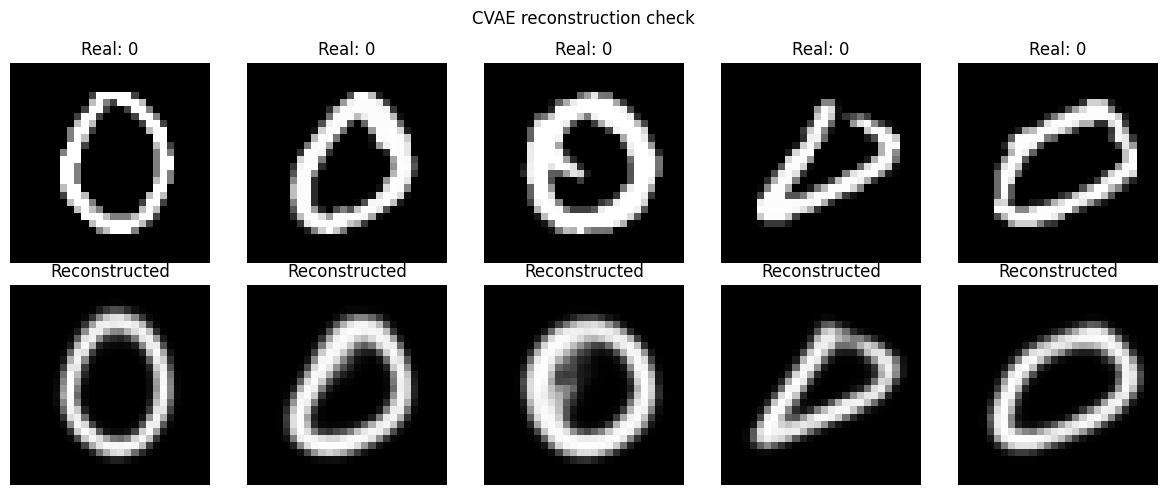

In [11]:
# ============================================================
# CELL 10 — Quick visual check: reconstruct real images
# ============================================================

sample_imgs = normalize_vae(train_images_350[:5])[..., np.newaxis]
sample_imgs = tf.convert_to_tensor(sample_imgs, dtype=tf.float32)

sample_labs = tf.constant(
    train_labels_350[:5].reshape(-1,1),
    dtype=tf.int32
)

# Encode
_, _, z = encoder([sample_imgs, sample_labs], training=False)

# Decode
reconstructed = decoder([z, sample_labs], training=False).numpy()

# Plot
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(sample_imgs[i, :, :, 0], cmap='gray')
    axes[0, i].set_title(f"Real: {train_labels_350[i]}")
    axes[0, i].axis('off')

    axes[1, i].imshow(reconstructed[i, :, :, 0], cmap='gray')
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis('off')

plt.suptitle("CVAE reconstruction check")
plt.tight_layout()
plt.show()

In [12]:
test_images, test_labels = balanced_subsample(test_images_full, test_labels_full, 200)
test_images = test_images/255

In [13]:
from tensorflow.keras import layers, models
# ============================================================
# Helper: build + train classifier, return accuracy
# ============================================================
def build_classifier():
    model = models.Sequential([
        layers.Conv2D(6, (5,5), activation='relu', input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),
        
        layers.Conv2D(16, (5,5), activation='relu'),
        layers.MaxPooling2D((2,2)),
        
        layers.Flatten(),
        
        layers.Dense(120, activation='relu'),
        layers.Dense(84, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

def train_and_evaluate(real_imgs, real_labs,
                       gen_imgs=None, gen_labs=None,
                       epochs=15, label=""):
    """Train classifier on real (+ optional synthetic) data, return test accuracy."""
    if gen_imgs is not None:
        X = np.concatenate([real_imgs, gen_imgs])[..., np.newaxis]
        y = np.concatenate([real_labs, gen_labs])
    else:
        X = real_imgs[..., np.newaxis]
        y = real_labs

    X = X.astype(np.float32)   # already [0,1]

    clf = build_classifier()
    t0  = time.time()
    clf.fit(X, y, epochs=epochs, batch_size=64, verbose=0)
    clf_time = time.time() - t0

    _, acc = clf.evaluate(test_images, test_labels, verbose=1)
    print(f"  {label:<50} | Acc: {acc*100:.2f}% | Time: {clf_time:.1f}s")
    return clf, acc

real_imgs, real_labs = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,350)
real_imgs = real_imgs / 255.0

In [14]:
# Baseline: real data only
clf, acc = train_and_evaluate(
    real_imgs,
    real_labs,
    label=f"{350} real only"
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1778508631.841364     136 service.cc:152] XLA service 0x2f73a280 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778508631.841425     136 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1778508631.841434     136 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1778508633.964901     136 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9762 - loss: 0.0965
  350 real only                                      | Acc: 96.55% | Time: 7.7s


In [15]:
# ============================================================
# CELL 12 — Generate 5 runs × 1000 images per digit
# Each run uses different random latent vectors z ~ N(0,I)
# ============================================================
def generate_vae_run(decoder, n_per_digit=1000, latent_dim=LATENT_DIM):
    """Sample z ~ N(0,I) and decode with label conditioning."""
    all_imgs, all_labs = [], []
    for digit in range(10):
        z      = tf.random.normal([n_per_digit, latent_dim])   # z ~ N(0,I)
        labels = tf.constant([[digit]] * n_per_digit, dtype=tf.int32)
        imgs   = decoder([z, labels], training=False).numpy()  # sigmoid → [0,1]
        all_imgs.append(imgs[:, :, :, 0])
        all_labs.append(np.full(n_per_digit, digit, dtype=np.int32))
    return np.vstack(all_imgs), np.hstack(all_labs)


def score_images(images, scorer_model):
    """Confidence = max(softmax) for each image."""
    X     = images[..., np.newaxis].astype(np.float32)
    probs = scorer_model.predict(X, batch_size=256, verbose=0)
    return np.max(probs, axis=1)


N_RUNS      = 5
N_PER_DIGIT = 1000

print(f"Generating {N_RUNS} runs × {N_PER_DIGIT}/digit × 10 digits "
      f"= {N_RUNS*N_PER_DIGIT*10} total VAE images...\n")

all_imgs, all_labs, all_conf = [], [], []

gen_start = time.time()
for run in range(N_RUNS):
    imgs, labs = generate_vae_run(decoder, N_PER_DIGIT, LATENT_DIM)
    conf       = score_images(imgs, clf)
    all_imgs.append(imgs)
    all_labs.append(labs)
    all_conf.append(conf)
    print(f"  Run {run+1}: mean confidence = {conf.mean():.3f} | "
          f"high (≥0.9): {(conf>=0.9).sum()} | "
          f"mid (0.6-0.9): {((conf>=0.6)&(conf<0.9)).sum()}")

print(f"\nGeneration time: {time.time()-gen_start:.1f}s")

pool_imgs = np.vstack(all_imgs)
pool_labs = np.hstack(all_labs)
pool_conf = np.hstack(all_conf)
print(f"Total pooled: {pool_imgs.shape[0]} images")

Generating 5 runs × 1000/digit × 10 digits = 50000 total VAE images...

  Run 1: mean confidence = 0.896 | high (≥0.9): 7074 | mid (0.6-0.9): 2002
  Run 2: mean confidence = 0.896 | high (≥0.9): 7042 | mid (0.6-0.9): 2013
  Run 3: mean confidence = 0.893 | high (≥0.9): 6969 | mid (0.6-0.9): 2062
  Run 4: mean confidence = 0.895 | high (≥0.9): 7002 | mid (0.6-0.9): 2051
  Run 5: mean confidence = 0.894 | high (≥0.9): 7005 | mid (0.6-0.9): 2033

Generation time: 3.5s
Total pooled: 50000 images


Set A (all):            50000 images
Set B (conf ≥ 0.9):     35092 images
Set C (0.6 ≤ c < 0.9):  10161 images


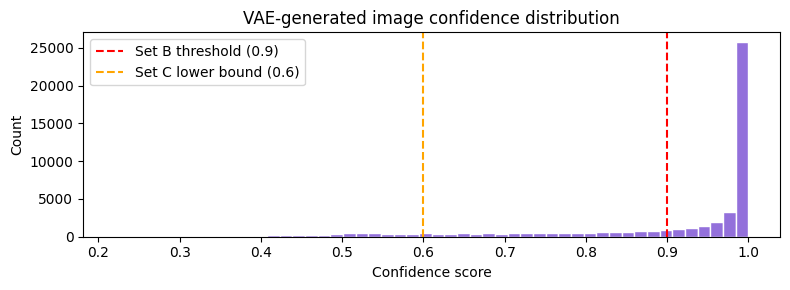

In [16]:
# ============================================================
# CELL 13 — Create Set A / B / C and show distribution
# ============================================================
mask_A = np.ones(len(pool_imgs), dtype=bool)
mask_B = pool_conf >= 0.9
mask_C = (pool_conf >= 0.6) & (pool_conf < 0.9)

set_A_imgs, set_A_labs = pool_imgs[mask_A], pool_labs[mask_A]
set_B_imgs, set_B_labs = pool_imgs[mask_B], pool_labs[mask_B]
set_C_imgs, set_C_labs = pool_imgs[mask_C], pool_labs[mask_C]

print(f"Set A (all):           {len(set_A_imgs):6d} images")
print(f"Set B (conf ≥ 0.9):    {len(set_B_imgs):6d} images")
print(f"Set C (0.6 ≤ c < 0.9): {len(set_C_imgs):6d} images")

plt.figure(figsize=(8, 3))
plt.hist(pool_conf, bins=50, color='mediumpurple', edgecolor='white')
plt.axvline(0.9, color='red',    linestyle='--', label='Set B threshold (0.9)')
plt.axvline(0.6, color='orange', linestyle='--', label='Set C lower bound (0.6)')
plt.xlabel('Confidence score')
plt.ylabel('Count')
plt.title('VAE-generated image confidence distribution')
plt.legend()
plt.tight_layout()
plt.show()

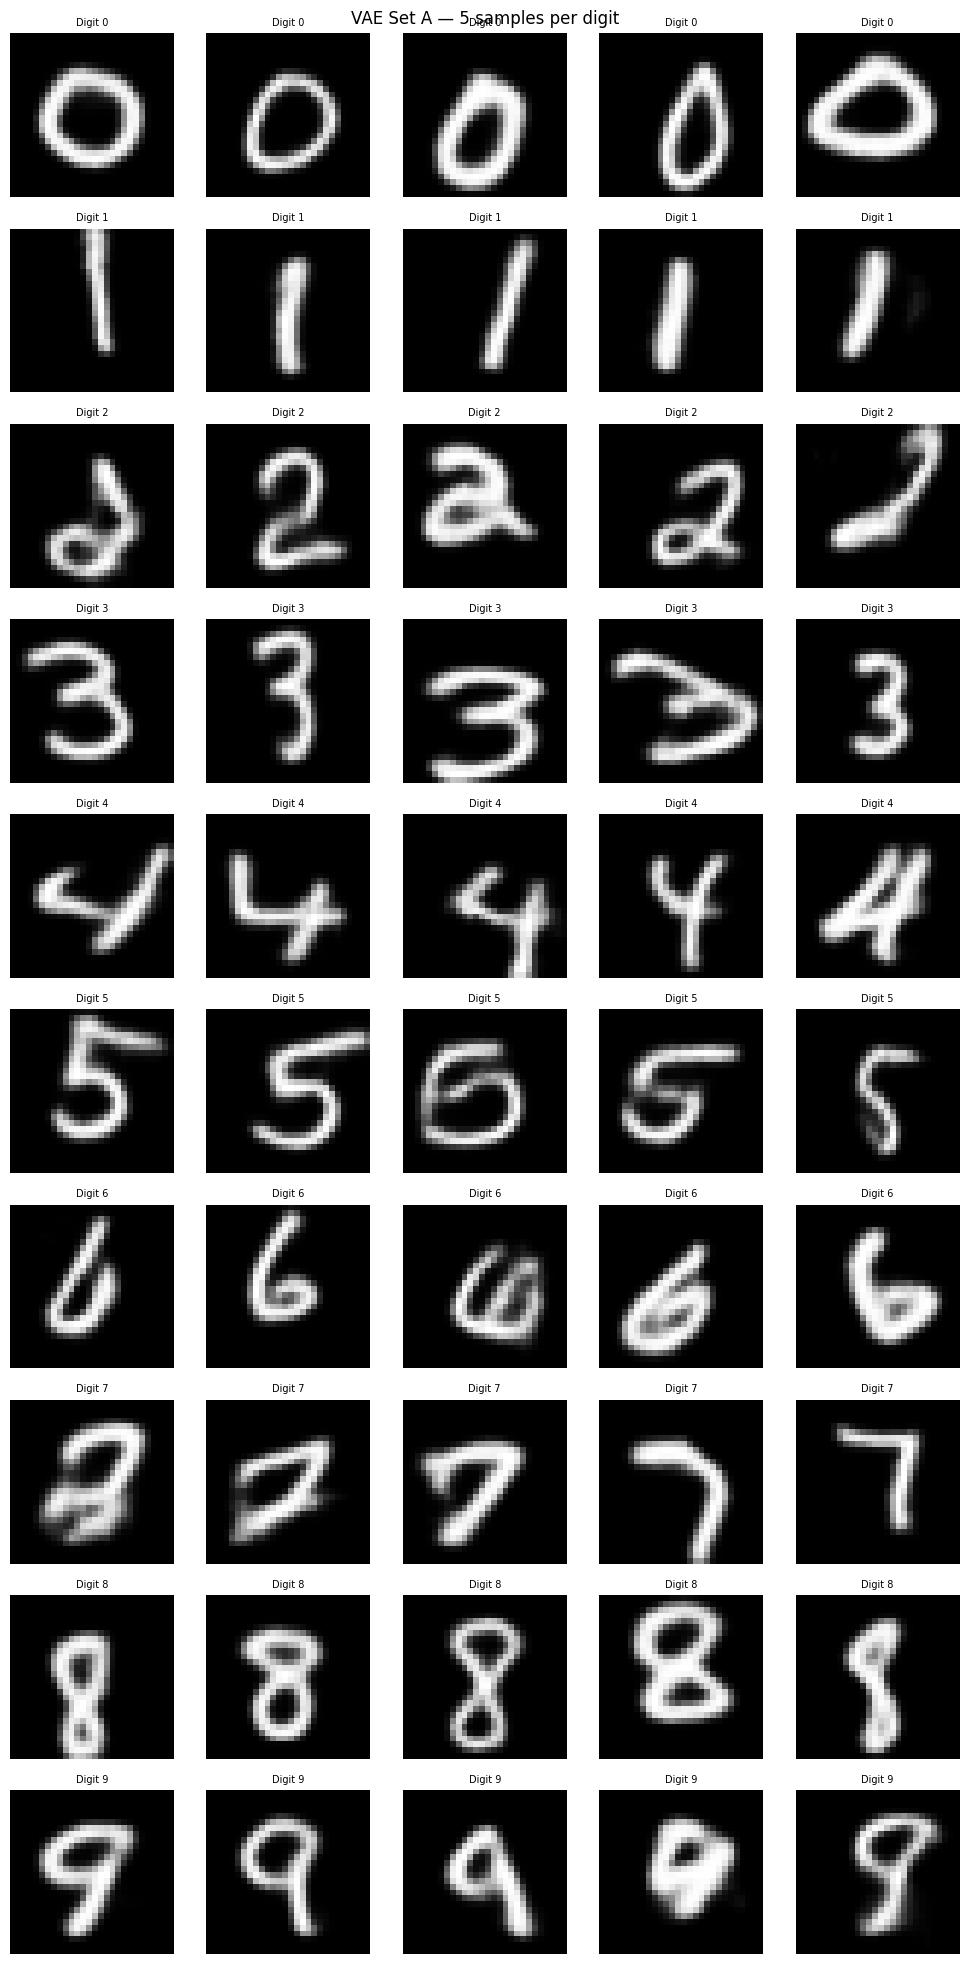

In [24]:
# ============================================================
# CELL 14 — Show sample generated images for visual inspection
# ============================================================
fig, axes = plt.subplots(10, 5, figsize=(10, 20))
for digit in range(10):
    digit_imgs = set_A_imgs[set_A_labs == digit][:5]
    for col in range(5):
        axes[digit, col].imshow(digit_imgs[col], cmap='gray')
        axes[digit, col].set_title(f"Digit {digit}", fontsize=7)
        axes[digit, col].axis('off')
plt.suptitle("VAE Set A — 5 samples per digit")
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CELL 16 — PART 1 Results Table
# ============================================================
print("=" * 80)
print("PART 1 — VAE Synthetic Data Results")
print("=" * 80)
print(f"  {'Configuration':<55} | {'Accuracy':>8} | Time")
print("-" * 80)

results_vae = {}

# Baseline A: 350 real only
real_imgs1, real_labs1 = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,350)
real_imgs1 = real_imgs1 / 255.0
acc = train_and_evaluate(real_imgs1, real_labs1,
                              label="Baseline: 350 real only")
results_vae['350_real_only'] = acc

# Baseline B: 1000 real only (gold standard)
real_imgs2, real_labs2 = balanced_subsample(train_images_full.astype(np.float32),train_labels_full,1000)
real_imgs2 = real_imgs2 / 255.0
acc = train_and_evaluate(real_imgs2, real_labs2,
                              label="Baseline: 1000 real only (gold standard)")
results_vae['1000_real_only'] = acc

# 350 real + augmented only (no VAE)
train_images_aug = train_images_aug / 255.0
acc = train_and_evaluate(train_images_aug, train_labels_aug,
                              label="350 real + augmentation only")
results_vae['350_aug_only'] = acc

# Set A, B, C
acc = train_and_evaluate(real_imgs1, real_labs1,
                              set_A_imgs, set_A_labs,
                              label="350 real + Set A (all VAE)")
results_vae['350_SetA'] = acc

acc = train_and_evaluate(real_imgs1, real_labs1,
                              set_B_imgs, set_B_labs,
                              label="350 real + Set B (conf ≥ 0.9)")
results_vae['350_SetB'] = acc

acc = train_and_evaluate(real_imgs1, real_labs1,
                              set_C_imgs, set_C_labs,
                              label="350 real + Set C (0.6 ≤ conf < 0.9)")
results_vae['350_SetC'] = acc

PART 1 — VAE Synthetic Data Results
  Configuration                                           | Accuracy | Time
--------------------------------------------------------------------------------
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9646 - loss: 0.1234
  Baseline: 350 real only                            | Acc: 95.00% | Time: 6.4s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9792 - loss: 0.0690
  Baseline: 1000 real only (gold standard)           | Acc: 97.50% | Time: 10.0s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9871 - loss: 0.0811 
  350 real + augmentation only                       | Acc: 98.30% | Time: 34.0s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9790 - loss: 0.0941
  350 real + Set A (all VAE)                         | Acc: 97.95% | Time: 34.2s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9804 - loss: 0.0881 
  350 real + Set B (conf ≥ 0.9)                      | Acc: 97.40% | Time: 24.6s
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/st